# TP2 — k -PPV et dimension sur SAheart


In [1]:
import sys; sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import balanced_accuracy_score, confusion_matrix
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score,
    cross_validate,
    train_test_split,
)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

import utils
utils.style()

GRAINE = 42

## Exercice 1 — Distance et standardisation


### 1.1 Données et découpage

In [2]:
variables = [
    "sbp", "tobacco", "ldl", "adiposity",
    "typea", "obesity", "alcohol", "age",
]

df = utils.load_saheart()
X = df[variables]
y = df["chd"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    stratify=y,
    random_state=GRAINE,
)

print(X_train.shape, X_test.shape)
print(y_train.value_counts(normalize=True).sort_index())

(346, 8) (116, 8)
chd
0    0.653179
1    0.346821
Name: proportion, dtype: float64


**Question**

1. Tại sao phải có **stratify = y** là do hiện tại ta đang split, chia ra để train model và ta đang muốn cho nó có 1 cái tỉ lệ của y gần giống với dữ liệu ban đầu nếu ko thì việc chia tỉ lệ sẽ được chia ngẫu nhiên. 

2. Tập test dùng để đánh giá cuối cùng mô hình sau khi bạn đã chọn mô hình.

3. Thường thì tập test ko được dùng để lựa chọn model 

### 1.2 Des unités incompatibles

In [10]:
resume = pd.DataFrame({
    "min": X_train.min(),
    "max": X_train.max(),
})

resume["etendue"] = resume["max"] - resume["min"]

print(resume)


              min     max  etendue
sbp        101.00  218.00   117.00
tobacco      0.00   31.20    31.20
ldl          0.98   15.33    14.35
adiposity    6.74   42.49    35.75
typea       13.00   78.00    65.00
obesity     17.75   45.72    27.97
alcohol      0.00  145.29   145.29
age         15.00   64.00    49.00


### 1.3 Comparaison brute / standardisée

In [ ]:
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=GRAINE,)

modele_brut = KNeighborsClassifier(n_neighbors=5)

modele_standardise = make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=5),)

score_brut = cross_val_score(
    modele_brut,
    X_train,
    y_train,
    cv=cv,
    scoring="balanced_accuracy",
).mean()

score_standardise = cross_val_score(
    modele_standardise,
    X_train,
    y_train,
    cv=cv,
    scoring="balanced_accuracy",
).mean()

print(f"brut : {score_brut:.3f}")
print(f"standardisé : {score_standardise:.3f}")

brut : 0.549
standardisé : 0.569


## Exercice 2 - Choisir k

### 2.1 La grille

In [12]:
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=GRAINE,
)

ks = list(range(1, 51))

erreurs_app = []
erreurs_val = []

for k in ks:

    modele = make_pipeline(
        StandardScaler(),
        KNeighborsClassifier(n_neighbors=k),
    )

    scores = cross_validate(
        modele,
        X_train,
        y_train,
        cv=cv,
        scoring="balanced_accuracy",
        return_train_score=True,
    )

    erreur_app = 1 - scores["train_score"].mean()
    erreur_val = 1 - scores["test_score"].mean()

    erreurs_app.append(erreur_app)
    erreurs_val.append(erreur_val)

k_optimal = ks[erreurs_val.index(min(erreurs_val))]

print(f"k choisi : {k_optimal}")

k choisi : 23


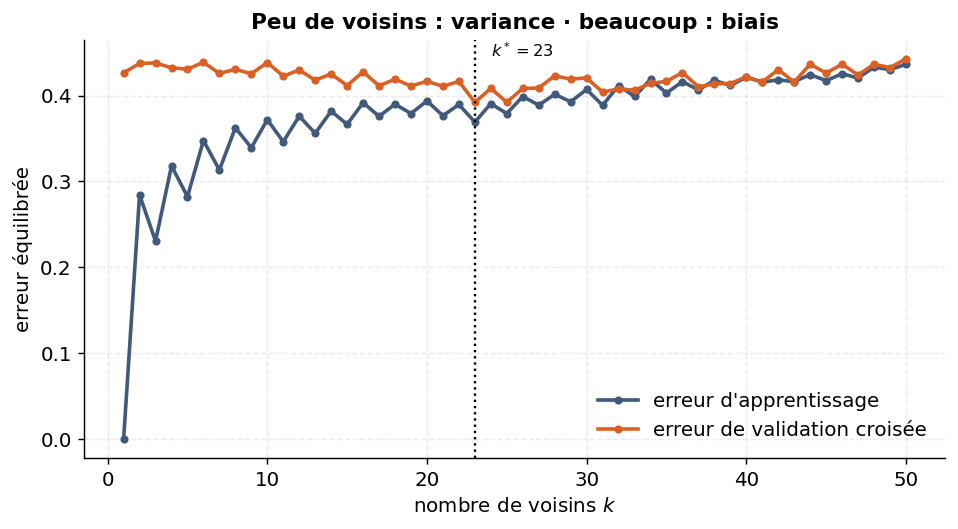

In [15]:
fig = utils.plot_courbe_kppv(
    ks,
    erreurs_app,
    erreurs_val,
    best_k=k_optimal
)

### 2.3 Évaluation finale